In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

import sys
import os
from tqdm import tqdm

sys.path.insert(0, os.path.join(os.getcwd(), ".", "scripts"))
from utility_functions import overlap, true_not_predicted, predicted_not_true, charge, \
    make_tada_intervals, make_paddle_intervals, make_adhunter_intervals, not_predicted_not_true, AD_coords, \
    make_adhunter_ensemble_intervals, make_adpred_intervals, read_parrot_preds

In [2]:
# Parameters to make figures work better with illustrator 
import matplotlib 
# For higher resoltion figures
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams["font.family"] = "Helvetica"
plt.rcParams['pdf.fonttype'] = 42

In [3]:
color_dict = {
    'TADA' : 'green',
    'ADpred' : 'dodgerblue',
    'ADhunterEnsemble' : 'red', 
    'ADhunterLite' : 'orange',
    'Paddle' : 'purple',
    'CADNN' : 'black'
}

In [4]:
def get_AD_coords(row, column='medium_ads'):
    ad_seqs = ast.literal_eval(row[column])
    sequence = row['sequence']

    coords = []

    for seq in ad_seqs: 
        start = sequence.find(seq) 
        end = start + len(seq)
        coords.append((start, end))

        # Check 
        if sequence[start:end] != seq:
            print(sequence)
            print(seq)
            print("ERROR")
    
    return coords

In [5]:
# Read in predictions from individual predictors
individual_predictions_sanborn = pd.read_csv('sanborn_seqs_for_testing_consensus/paddle_test_seqs_combined_all_six.csv',
                                     index_col=0, 
                                     converters={'combined_preds' : ast.literal_eval, 
                                                })

individual_predictions_arnold = pd.read_csv('arnold_seqs_for_testing_consensus/arnold_seqs_with_ADs_combined_all_six.csv',
                                     index_col=0, 
                                     converters={'combined_preds' : ast.literal_eval, 
                                                })

individual_predictions_arf = pd.read_csv('arf_seqs_for_testing_consensus/arf_seqs_combined_all_six.csv',
                                     index_col=0, 
                                     converters={'combined_preds' : ast.literal_eval, 
                                                })

individual_predictions_delrosso = pd.read_csv('delrosso_seqs_for_testing_consensus/delrosso_test_TFs_w_ADs_combined_all_six.csv',
                                     index_col=0, 
                                     converters={'combined_preds' : ast.literal_eval, 
                                                })
individual_predictions = pd.concat([individual_predictions_sanborn, individual_predictions_arnold, individual_predictions_arf, individual_predictions_delrosso], ignore_index=True)

# Convert to lists of tuples
individual_predictions['adhunter_intervals'] = individual_predictions['adhunter_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_centers'] = individual_predictions['adhunter_centers'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_preds'] = individual_predictions['adhunter_preds'].fillna('[]').apply(ast.literal_eval)


individual_predictions['tada_intervals'] = individual_predictions['tada_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_centers'] = individual_predictions['tada_centers'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_preds'] = individual_predictions['tada_preds'].fillna('[]').apply(ast.literal_eval)

individual_predictions['adpred_intervals'] = individual_predictions['adpred_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adpred_preds'] = individual_predictions['adpred_preds'].fillna('[]').apply(ast.literal_eval)

individual_predictions['paddle_intervals'] = individual_predictions['paddle_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['paddle_centers'] = individual_predictions['paddle_centers'].apply(ast.literal_eval)
individual_predictions['paddle_preds'] = individual_predictions['paddle_preds'].apply(ast.literal_eval)

individual_predictions['adhunter_ensemble_intervals'] = individual_predictions['adhunter_ensemble_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_preds'] = individual_predictions['adhunter_ensemble_preds'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_centers'] = individual_predictions['adhunter_ensemble_centers'].fillna('[]').apply(ast.literal_eval)

individual_predictions['composition_intervals'] = individual_predictions['composition_intervals'].fillna('[]').apply(ast.literal_eval)

In [7]:
sanborn_consensus_preds = read_parrot_preds('sanborn_seqs_for_testing_consensus/sanborn_seqs_consensus_all_six_preds.tsv')
arnold_consensus_preds = read_parrot_preds('arnold_seqs_for_testing_consensus/arnold_seqs_consensus_all_six_preds.tsv')
arnold_consensus_preds['name'] = arnold_consensus_preds['name'].str.replace(">", "")
arf_consensus_preds = read_parrot_preds('arf_seqs_for_testing_consensus/arf_seqs_consensus_all_six_preds.tsv')
delrosso_consensus_preds = read_parrot_preds('delrosso_seqs_for_testing_consensus/delrosso_seqs_consensus_all_six_preds.tsv')

consensus_preds = pd.concat([sanborn_consensus_preds, arnold_consensus_preds, arf_consensus_preds, delrosso_consensus_preds], ignore_index=True)

In [17]:
arnold_consensus_preds

,name,sequence,preds
0,HLH3B_FBtr0070506,MAWLPSSSNGADNADERSTASSGSSGHSQTNESPRSGHLNGNGSMR...,"[-0.0018510865, 0.005008566, -0.018818345, -0...."
1,MTF-1_FBtr0113324,MRTHTQERPYKCPEDDCGKAFTASHHLKTHRRTHTGEKPYPCQEDS...,"[-0.041248154, -0.03127392, -0.034103204, -0.0..."
2,sage_FBtr0081982,MTDQLLSSTAGVPGDPPPVLVPVSATTGGPYLSGGSEGEAESSEQP...,"[-0.0013642488, -0.00061782915, 0.0025258148, ..."
3,CG14451_FBtr0078538,MENRRCTVVAVGDLVDELGFCCEWCGKVYKSLVRYHNHIVCTHKLP...,"[0.16041979, 0.17354545, 0.14955525, 0.1437678..."
4,bin_FBtr0076900,MIKSEEASDRSVMTMDQLGGYYHDPRAHPPFSHPHAHSHPHQHTHT...,"[-0.041808616, -0.05450045, -0.036633268, -0.0..."
5,pdm2_FBtr0080392,MPLLLATTLANNSHHQHLSTTATETAAAAATAKAAATAAAAATATM...,"[-0.021099854, -0.004025516, -0.0357443, -0.03..."
6,Hnf4_FBtr0079747,MMKHPQDLSVTDDQQLMKVNKVEKMEQELHDPESESHIMHADALAS...,"[-0.038901165, -0.04978424, -0.026281338, -0.0..."
7,Bteb2_FBtr0070735,MDFFATGGFQQLYSDLEEEPLAGGDALLNIVSVGEFDSTYVDTSFS...,"[0.6225795, 0.64430994, 0.5879901, 0.5935061, ..."
8,rgr_FBtr0088692,MMPLQESPSPSWQLEDYAFFRKCGEITVSPDVQSFGFNCAFCPAIC...,"[0.36690363, 0.3484056, 0.39244682, 0.37786537..."
9,E2f_FBtr0084119,MSKFFVNVAPINNSNSSSSHTTTSSNTQRHQQHQQHYGGSGTTGHT...,"[-0.03282835, -0.016302, -0.014739235, -0.0100..."


In [16]:
delrosso_consensus_preds['sequence'].str.len().sum()

np.int64(13895)

In [7]:
# Read in experimental data
sanborn_data = pd.read_csv('sanborn_seqs_for_testing_consensus/paddle_test_seqs.csv', index_col=0)

# Make it so that each row is a protein (instead of each row is an AD)
sanborn_data = (
    sanborn_data.assign(real_AD_coords=list(zip(sanborn_data["start"], sanborn_data["stop"])))
        .groupby(["protein", "protein ID", 'protein sequence'], as_index=False)["real_AD_coords"]
        .agg(list)
)
sanborn_data = sanborn_data.rename(columns={'protein' : 'name', 'protein sequence' : 'sequence'})

# Arnold data 
arnold_data = pd.read_csv('arnold_seqs_for_testing_consensus/arnold_seqs_with_short_ADs.csv', index_col=0)
arnold_data['ad_charge'] = arnold_data['sequence'].apply(charge)
arnold_data['start'] = (arnold_data["start tAD [relative to TF CDS]"] / 3).astype(int)
arnold_data['end'] = (arnold_data["end tAD [relative to TF CDS]"] / 3).astype(int)

# Make it so that each row is a protein (instead of each row is an AD)
arnold_data = (
    arnold_data.assign(real_AD_coords=list(zip(arnold_data["start"], arnold_data["end"])))
        .groupby(["TF_name", 'protein_seq'], as_index=False)["real_AD_coords"]
        .agg(list)
)
arnold_data = arnold_data.rename(columns={'TF_name' : 'name', 'protein_seq' : 'sequence'})


# Arf data 
arf_data = pd.read_csv('arf_seqs_for_testing_consensus/arf_seqs_w_ADs.csv', index_col=0)

# Drop rows with identical sequences
arf_consensus_names = arf_consensus_preds['name']
arf_data = arf_data[[n in set(arf_consensus_names) for n in arf_data['name']]]
arf_data['real_AD_coords'] = arf_data.apply(get_AD_coords, axis=1)

# Delrosso data 
# Read in experimental data
delrosso_data = pd.read_csv('delrosso_seqs_for_testing_consensus/delrosso_test_TFs_w_ADs.csv', index_col=0)

# The sequences are from lambert while the ADs are from delrosso
# Therefore, there is a slight difference with one AD not matching the sequence from lambert

# Make it so that each row is a protein (instead of each row is an AD)
delrosso_data = (
    delrosso_data.assign(real_AD_coords=list([(s, e) if not np.isnan(s) else () for s, e in zip(delrosso_data["Start"], delrosso_data["End"])]))
        .groupby(["UniProt ID", 'full_seq'], as_index=False)["real_AD_coords"]
        .agg(list)
)
delrosso_data = delrosso_data.rename(columns={'UniProt ID' : 'name', 'full_seq' : 'sequence'})
delrosso_data['real_AD_coords'] = [[] if ls[0] == () else [(int(s), int(e)) for s, e in ls] for ls in delrosso_data['real_AD_coords']]


data = pd.concat([sanborn_data[['name', 'sequence', 'real_AD_coords']], 
                  arnold_data[['name', 'sequence', 'real_AD_coords']], 
                  arf_data[['name', 'sequence', 'real_AD_coords']], 
                  delrosso_data[['name', 'sequence', 'real_AD_coords']]],
                  ignore_index=True)

# data = arnold_data[['name', 'sequence', 'real_AD_coords']]
merged_individual = individual_predictions.merge(data, on=['name', 'sequence'], how='right') 
merged_consensus = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

# Doing it the easy way

In [8]:
tada_pred_ls = []
adhunterlite_pred_ls = []
parrot_ls = []
real_ls = []
paddle_ls = []
adhunterensemble_ls = []
adpred_ls = []

# Note: We are treating each tile as a single prediction at the tile center
# Is that fair??

for i in merged_individual.index: 
    if len(merged_individual.loc[i, 'sequence']) < 53:
        continue
    # Add padding to predictions (Not exactly what's going on when we call intervals)
    tada_pred_ls += [merged_individual.loc[i, 'tada_preds'][0]] * 20 + \
                list(merged_individual.loc[i, 'tada_preds']) + \
                    [merged_individual.loc[i, 'tada_preds'][-1]] * 19 
    
    adhunterlite_pred_ls += [merged_individual.loc[i, 'adhunter_preds'][0]] * 20 + \
                list(merged_individual.loc[i, 'adhunter_preds']) + \
                    [merged_individual.loc[i, 'adhunter_preds'][-1]] * 19 
    
    # Check PADDLE coords
    paddle_ls += [merged_individual.loc[i, 'paddle_preds'][0]] * 27 + \
                list(merged_individual.loc[i, 'paddle_preds']) + \
                    [merged_individual.loc[i, 'paddle_preds'][-1]] * 25
    
    adhunterensemble_ls += [merged_individual.loc[i, 'adhunter_ensemble_preds'][0]] * 27 + \
                list(merged_individual.loc[i, 'adhunter_ensemble_preds']) + \
                    [merged_individual.loc[i, 'adhunter_ensemble_preds'][-1]] * 25
    
    real = [0] * len(merged_consensus.loc[i, 'sequence'])
    for start, end in merged_consensus.loc[i, 'real_AD_coords']: 
        real[start:end] = [1] * (end-start)

    parrot_ls += list(merged_consensus.loc[i, 'preds'])
    adpred_ls += list(merged_individual.loc[i, 'adpred_preds'])
    
    real_ls += real
    

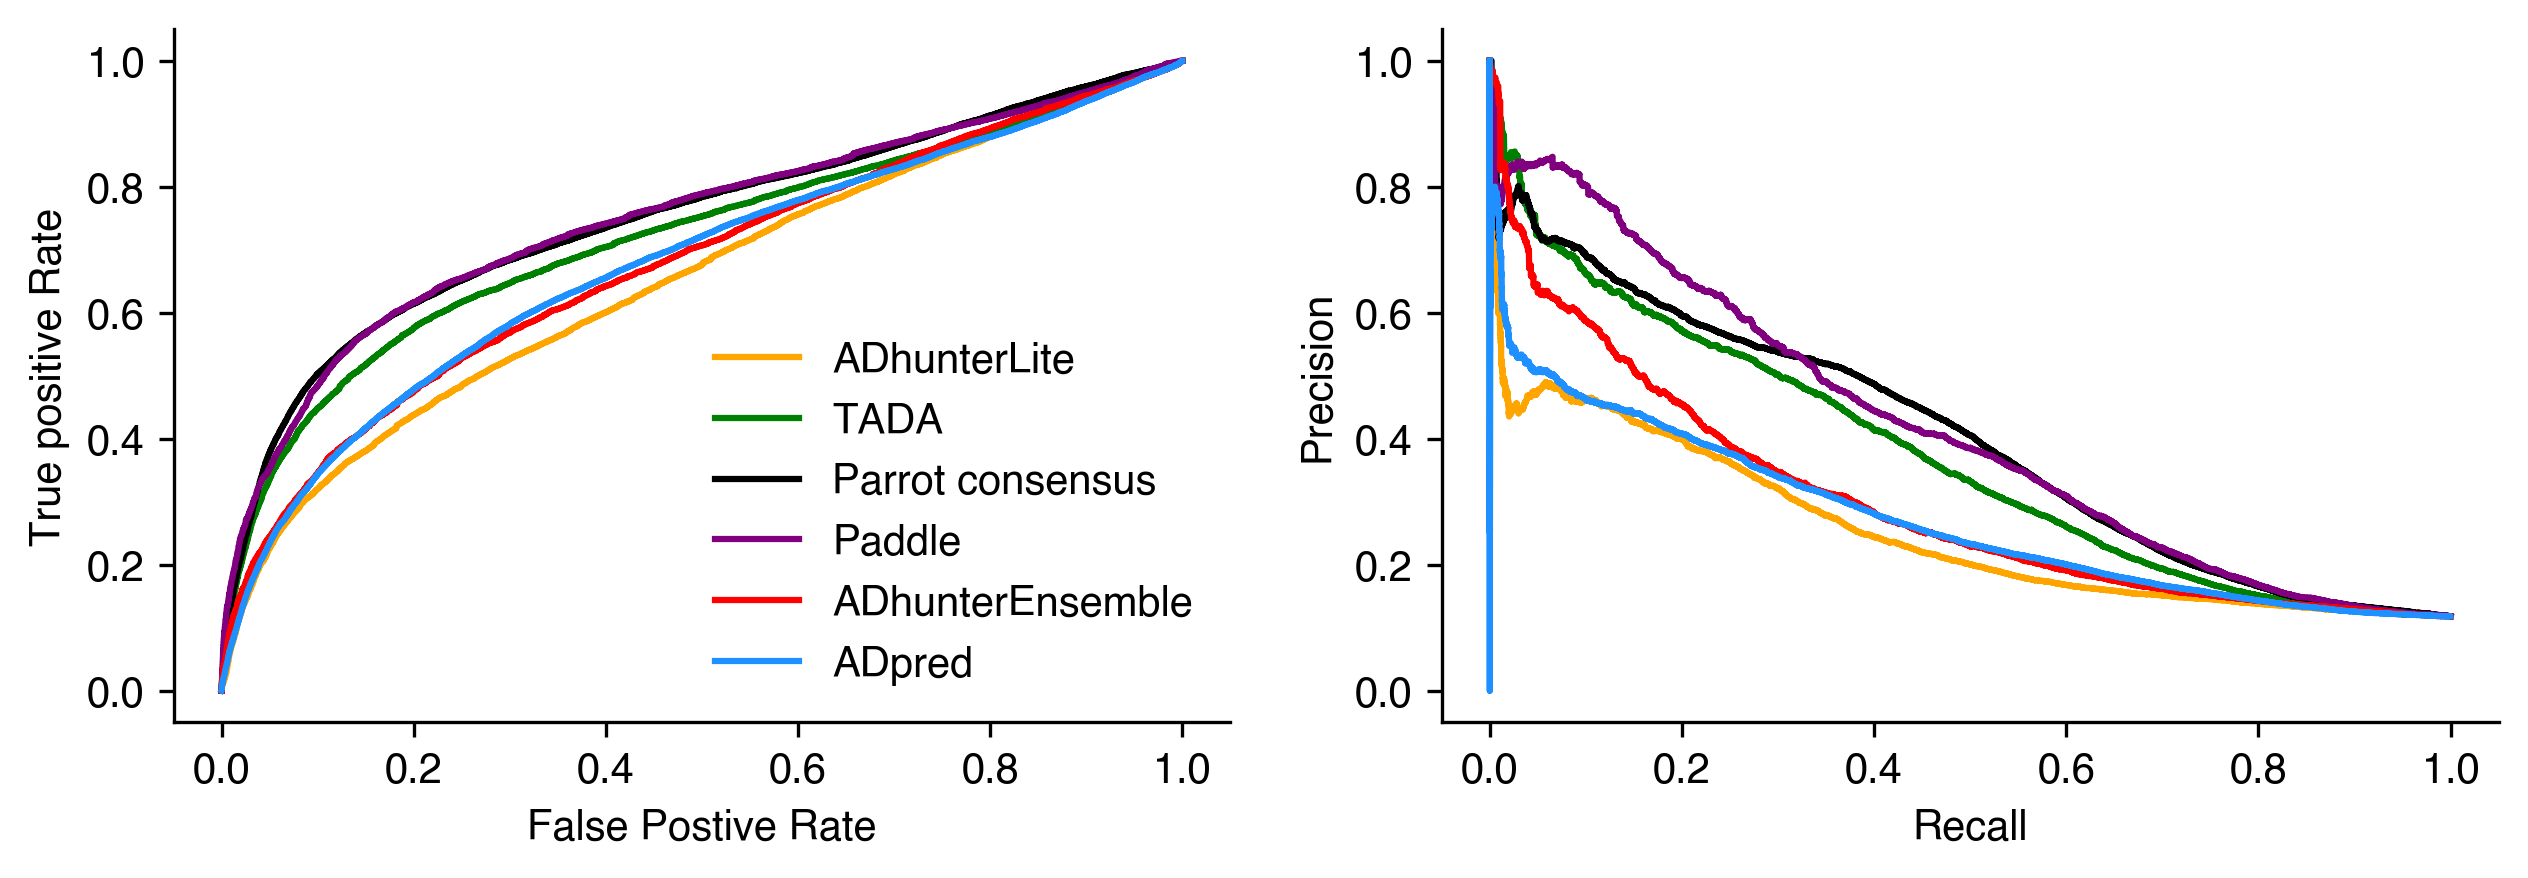

In [9]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

adhunterlite_fpr, adhunterlite_tpr, _ = roc_curve(real_ls, adhunterlite_pred_ls)
tada_fpr, tada_tpr, _ = roc_curve(real_ls, tada_pred_ls)
parrot_fpr, parrot_tpr, _ = roc_curve(real_ls, parrot_ls)
paddle_fpr, paddle_tpr, _ = roc_curve(real_ls, paddle_ls)
adhunter_e_fpr, adhunter_e_tpr, _ = roc_curve(real_ls, adhunterensemble_ls)
adpred_fpr, adpred_tpr, _ = roc_curve(real_ls, adpred_ls)

adhunterlite_prec, adhunterlite_rec, adhunterlite_thresh = precision_recall_curve(real_ls, adhunterlite_pred_ls)
tada_prec, tada_rec, tada_thresh = precision_recall_curve(real_ls, tada_pred_ls)
parrot_prec, parrot_rec, parrot_thresh = precision_recall_curve(real_ls, parrot_ls)
paddle_prec, paddle_rec, paddle_thresh = precision_recall_curve(real_ls, paddle_ls)
adhunter_e_prec, adhunter_e_rec, adhunter_e_thresh = precision_recall_curve(real_ls, adhunterensemble_ls)
adpred_prec, adpred_rec, adpred_thresh = precision_recall_curve(real_ls, adpred_ls)

axs[0].plot(adhunterlite_fpr, adhunterlite_tpr, label='ADhunterLite', color = color_dict['ADhunterLite'])
axs[0].plot(tada_fpr, tada_tpr, label='TADA', color = color_dict['TADA'])
axs[0].plot(parrot_fpr, parrot_tpr, label='Parrot consensus', color = 'black')
axs[0].plot(paddle_fpr, paddle_tpr, label='Paddle', color = color_dict['Paddle'])
axs[0].plot(adhunter_e_fpr, adhunter_e_tpr, label='ADhunterEnsemble', color = color_dict['ADhunterEnsemble'])
axs[0].plot(adpred_fpr, adpred_tpr, label='ADpred', color = color_dict['ADpred'])
axs[0].legend(frameon=False)
axs[0].set_xlabel("False Postive Rate")
axs[0].set_ylabel("True positive Rate")

axs[1].plot(adhunterlite_rec, adhunterlite_prec,  label='ADhunterLite', color = color_dict['ADhunterLite'])
axs[1].plot(tada_rec, tada_prec, label='TADA', color = color_dict['TADA'])
axs[1].plot(parrot_rec, parrot_prec, label='Parrot consensus', color='black')
axs[1].plot(paddle_rec, paddle_prec, label='Paddle', color = color_dict['Paddle'])
axs[1].plot(adhunter_e_rec, adhunter_e_prec, label='ADhunterEnsemble', color = color_dict['ADhunterEnsemble'])
axs[1].plot(adpred_rec, adpred_prec, label='ADpred', color = color_dict['ADpred'])
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precision")

sns.despine()

# Doing it the hard way

In [10]:
# Beacuse the threshold biases the F1 score so much, I think PRC curves are a better choice

def calculate_precision_recall_tada(threshold):
    intervals = make_tada_intervals(individual_predictions, threshold)
    if (intervals is None) or (len(intervals) == 0): # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['TADA'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_paddle(threshold):
    intervals = make_paddle_intervals(individual_predictions, threshold)
    if (intervals is None) or (len(intervals) == 0): # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))
    
    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['PADDLE'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adhunterlite(threshold):
    intervals = make_adhunter_intervals(individual_predictions, threshold)
    if (intervals is None) or (len(intervals) == 0): # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADHunter'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adhunterensemble(threshold):
    intervals = make_adhunter_ensemble_intervals(individual_predictions, threshold)
    if (intervals is None) or (len(intervals) == 0): # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADHunter_ensemble'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)


    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adpred(threshold):
    intervals = make_adpred_intervals(individual_predictions, threshold)
    if len(intervals) == 0: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADPred'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_parrot(threshold):
    consensus_preds['predicted_AD_coords'] = consensus_preds['preds'].apply(AD_coords, threshold=threshold)

    merged = consensus_preds.merge(data, on=['name', 'sequence'], how='right')
    tp = merged.apply(overlap, ad_coords_col='predicted_AD_coords', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='predicted_AD_coords', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='predicted_AD_coords', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='predicted_AD_coords', axis=1).sum()

    parrot_r = tp / (tp + fn)

    if (tp + fp) == 0: 
        return 0, 1, 0, 0
    else: 
        parrot_p = tp / (tp + fp)

    parrot_tpr = tp / (tp + fn) # This is the same as recall
    parrot_fpr = fp / (fp + tn)

    return parrot_r, parrot_p, parrot_fpr, parrot_tpr



In [11]:
# protein_length-52 -1 is the final tile start

In [12]:
adhunter_e_recalls = []
adhunter_e_precisions = []
adhunter_e_fpr = []
adhunter_e_tpr = []

for threshold in tqdm(adhunter_e_thresh):
    r, p, fpr, tpr = calculate_precision_recall_adhunterensemble(threshold)
    adhunter_e_recalls.append(r)
    adhunter_e_precisions.append(p)    
    adhunter_e_fpr.append(fpr)
    adhunter_e_tpr.append(tpr)

100%|██████████| 136943/136943 [4:20:44<00:00,  8.75it/s]    


In [13]:
adpred_recalls = []
adpred_precisions = []
adpred_fpr = []
adpred_tpr = []

for threshold in tqdm(adpred_thresh):
    r, p, fpr, tpr = calculate_precision_recall_adpred(threshold)
    adpred_recalls.append(r)
    adpred_precisions.append(p)    
    adpred_fpr.append(fpr)
    adpred_tpr.append(tpr)

100%|██████████| 157570/157570 [20:10:33<00:00,  2.17it/s]     


In [14]:
adhunter_l_recalls = []
adhunter_l_precisions = []
adhunter_l_fpr = []
adhunter_l_tpr = []

for threshold in tqdm(adhunterlite_thresh):
    r, p, fpr, tpr = calculate_precision_recall_adhunterlite(threshold)
    adhunter_l_recalls.append(r)
    adhunter_l_precisions.append(p)    
    adhunter_l_fpr.append(fpr)
    adhunter_l_tpr.append(tpr)

100%|██████████| 141214/141214 [3:21:17<00:00, 11.69it/s]  


In [15]:
paddle_recalls = []
paddle_precisions = []
paddle_fpr = []
paddle_tpr = []

for threshold in tqdm(paddle_thresh):
    r, p, fpr, tpr = calculate_precision_recall_paddle(threshold)
    paddle_recalls.append(r)
    paddle_precisions.append(p)    
    paddle_fpr.append(fpr)
    paddle_tpr.append(tpr)

100%|██████████| 138784/138784 [5:17:19<00:00,  7.29it/s]  


In [16]:
tada_recalls = []
tada_precisions = []
tada_fpr = []
tada_tpr = []

for threshold in tqdm(tada_thresh):
    r, p, fpr, tpr = calculate_precision_recall_tada(threshold)
    tada_recalls.append(r)
    tada_precisions.append(p)    
    tada_fpr.append(fpr)
    tada_tpr.append(tpr)

100%|██████████| 140068/140068 [4:23:44<00:00,  8.85it/s]     


In [17]:
parrot_recalls = []
parrot_precisions = []
parrot_fpr = []
parrot_tpr = []

for threshold in tqdm(parrot_thresh):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold)
    parrot_recalls.append(r)
    parrot_precisions.append(p)    
    parrot_fpr.append(fpr)
    parrot_tpr.append(tpr)

100%|██████████| 159718/159718 [55:03<00:00, 48.34it/s]   


In [18]:
pd.DataFrame({'parrot_recalls' : parrot_recalls,
              'parrot_precisions' : parrot_precisions,
              'parrot_fpr' : parrot_fpr,
              'parrot_tpr' : parrot_tpr}).to_csv('all_data_parrot_roc_prc_data.csv')

In [19]:
pd.DataFrame({'tada_recalls' : tada_recalls,
              'tada_precisions' : tada_precisions,
              'tada_fpr' : tada_fpr,
              'tada_tpr' : tada_tpr}).to_csv('all_data_tada_roc_prc_data.csv')

In [20]:
pd.DataFrame({'adpred_recalls' : adpred_recalls,
              'adpred_precisions' : adpred_precisions,
              'adpred_fpr' : adpred_fpr,
              'adpred_tpr' : adpred_tpr}).to_csv('all_data_adpred_roc_prc_data.csv')

In [21]:
pd.DataFrame({'paddle_recalls' : paddle_recalls,
              'paddle_precisions' : paddle_precisions,
              'paddle_fpr' : paddle_fpr,
              'paddle_tpr' : paddle_tpr}).to_csv('all_data_paddle_roc_prc_data.csv')

In [22]:
pd.DataFrame({'adhunter_l_recalls' : adhunter_l_recalls,
              'adhunter_l_precisions' : adhunter_l_precisions,
              'adhunter_l_fpr' : adhunter_l_fpr,
              'adhunter_l_tpr' : adhunter_l_tpr}).to_csv('all_data_adhunter_l_roc_prc_data.csv')

In [23]:
pd.DataFrame({'adhunter_e_recalls' : adhunter_e_recalls,
              'adhunter_e_precisions' : adhunter_e_precisions,
              'adhunter_e_fpr' : adhunter_e_fpr,
              'adhunter_e_tpr' : adhunter_e_tpr}).to_csv('all_data_adhunter_e_roc_prc_data.csv')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


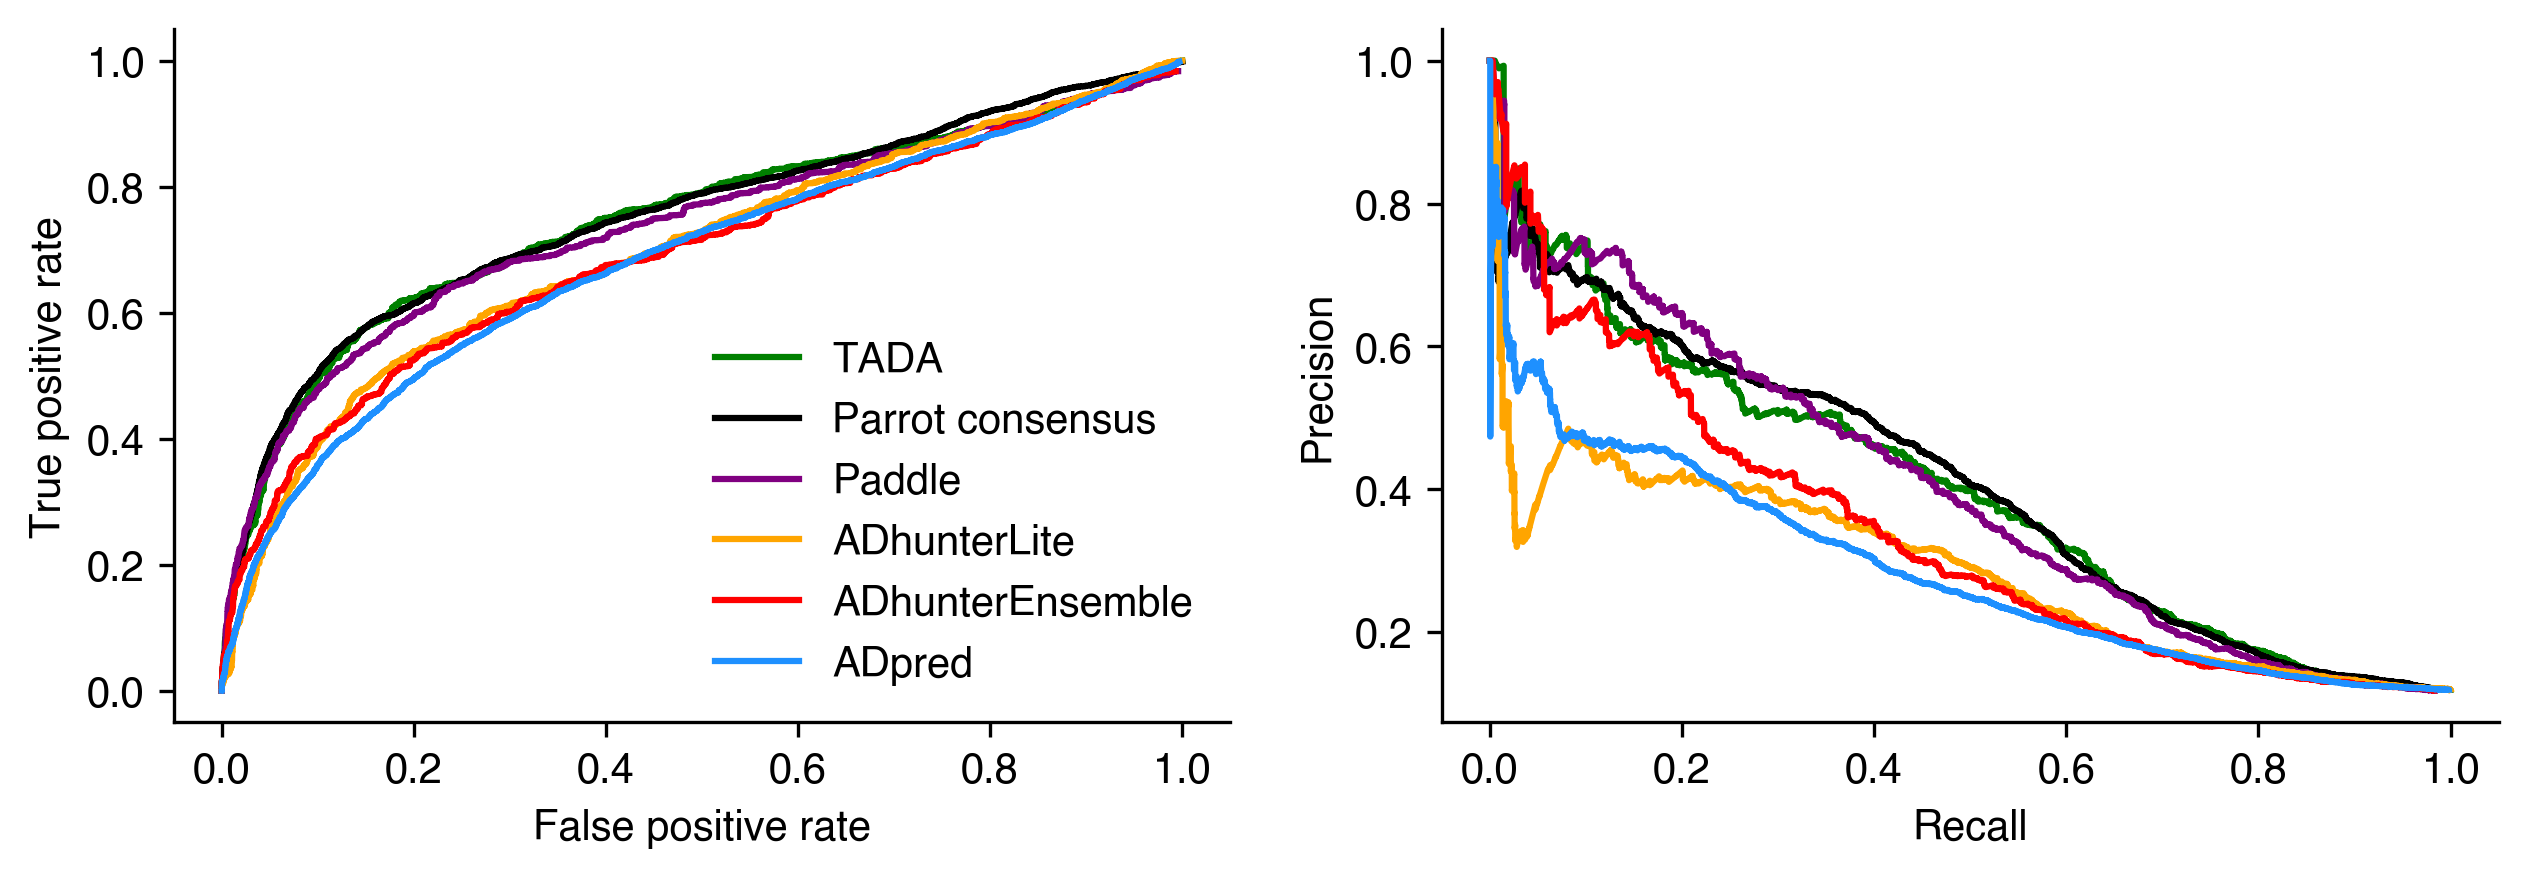

In [31]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].plot(tada_fpr, tada_tpr, label='TADA', color=color_dict['TADA'])
axs[0].plot(parrot_fpr, parrot_tpr, label='Parrot consensus', color='black')
axs[0].plot(paddle_fpr, paddle_tpr, label='Paddle', color=color_dict['Paddle'])
axs[0].plot(adhunter_l_fpr, adhunter_l_tpr, label='ADhunterLite', color=color_dict['ADhunterLite'])
axs[0].plot(adhunter_e_fpr, adhunter_e_tpr, label='ADhunterEnsemble', color=color_dict['ADhunterEnsemble'])
axs[0].plot(adpred_fpr, adpred_tpr, label='ADpred', color=color_dict['ADpred'])
axs[0].set_xlabel("False positive rate")
axs[0].set_ylabel("True positive rate")
axs[0].legend(frameon=False)

axs[1].plot(tada_recalls, tada_precisions, label='TADA', color=color_dict['TADA'])
axs[1].plot(parrot_recalls, parrot_precisions, label='Parrot consensus', color='black')
axs[1].plot(paddle_recalls, paddle_precisions, label='Paddle', color=color_dict['Paddle']) 
axs[1].plot(adhunter_l_recalls, adhunter_l_precisions, label='ADhunterLite', color=color_dict['ADhunterLite'])
axs[1].plot(adhunter_e_recalls, adhunter_e_precisions, label='ADhunterEnsemble', color=color_dict['ADhunterEnsemble'])
axs[1].plot(adpred_recalls, adpred_precisions, label='ADpred', color=color_dict['ADpred'])
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precision")

sns.despine()

plt.savefig("figures/all_combined_precision_recall.pdf", format='pdf', bbox_inches='tight')
plt.savefig("figures/all_combined_precision_recall.png", format='png', bbox_inches='tight')

In [32]:
from sklearn.metrics import auc

print(f"TADA PRC AUC: {auc(tada_recalls, tada_precisions):.3}")
print(f"Parrot consensus PRC AUC: {auc(parrot_recalls, parrot_precisions):.3}")
print(f"Paddle PRC AUC: {auc(paddle_recalls, paddle_precisions):.3}")
print(f"ADhunterLite PRC AUC: {auc(adhunter_l_recalls, adhunter_l_precisions):.3}")
print(f"ADhunterEnsemble PRC AUC: {auc(adhunter_e_recalls, adhunter_e_precisions):.3}")
print(f"ADpred PRC AUC: {auc(adpred_recalls, adpred_precisions):.3}")

TADA PRC AUC: 0.398
Parrot consensus PRC AUC: 0.404
Paddle PRC AUC: 0.397
ADhunterLite PRC AUC: 0.287
ADhunterEnsemble PRC AUC: 0.335
ADpred PRC AUC: 0.286


In [33]:
print(f"TADA ROC AUC: {auc(tada_fpr, tada_tpr):.3}")
print(f"Parrot consensus ROC AUC: {auc(parrot_fpr, parrot_tpr):.3}")
print(f"Paddle ROC AUC: {auc(paddle_fpr, paddle_tpr):.3}")
print(f"ADhunterLite ROC AUC: {auc(adhunter_l_fpr, adhunter_l_tpr):.3}")
print(f"ADhunterEnsemble ROC AUC: {auc(adhunter_e_fpr, adhunter_e_tpr):.3}")
print(f"ADpred ROC AUC: {auc(adpred_fpr, adpred_tpr):.3}")

TADA ROC AUC: 0.746
Parrot consensus ROC AUC: 0.751
Paddle ROC AUC: 0.73
ADhunterLite ROC AUC: 0.697
ADhunterEnsemble ROC AUC: 0.684
ADpred ROC AUC: 0.68


# Make plot of inidivual AUCs

In [27]:
# From plant: 
# TADA PRC AUC: 0.513
# Parrot consensus PRC AUC: 0.53
# Paddle PRC AUC: 0.414
# ADhunterLite PRC AUC: 0.364
# ADhunterEnsemble PRC AUC: 0.422
# ADpred PRC AUC: 0.439

In [28]:
# From sanborn 
# TADA PRC AUC: 0.588
# Parrot consensus PRC AUC: 0.515
# Paddle PRC AUC: 0.706
# ADhunterLite PRC AUC: 0.367
# ADhunterEnsemble PRC AUC: 0.394
# ADpred PRC AUC: 0.275

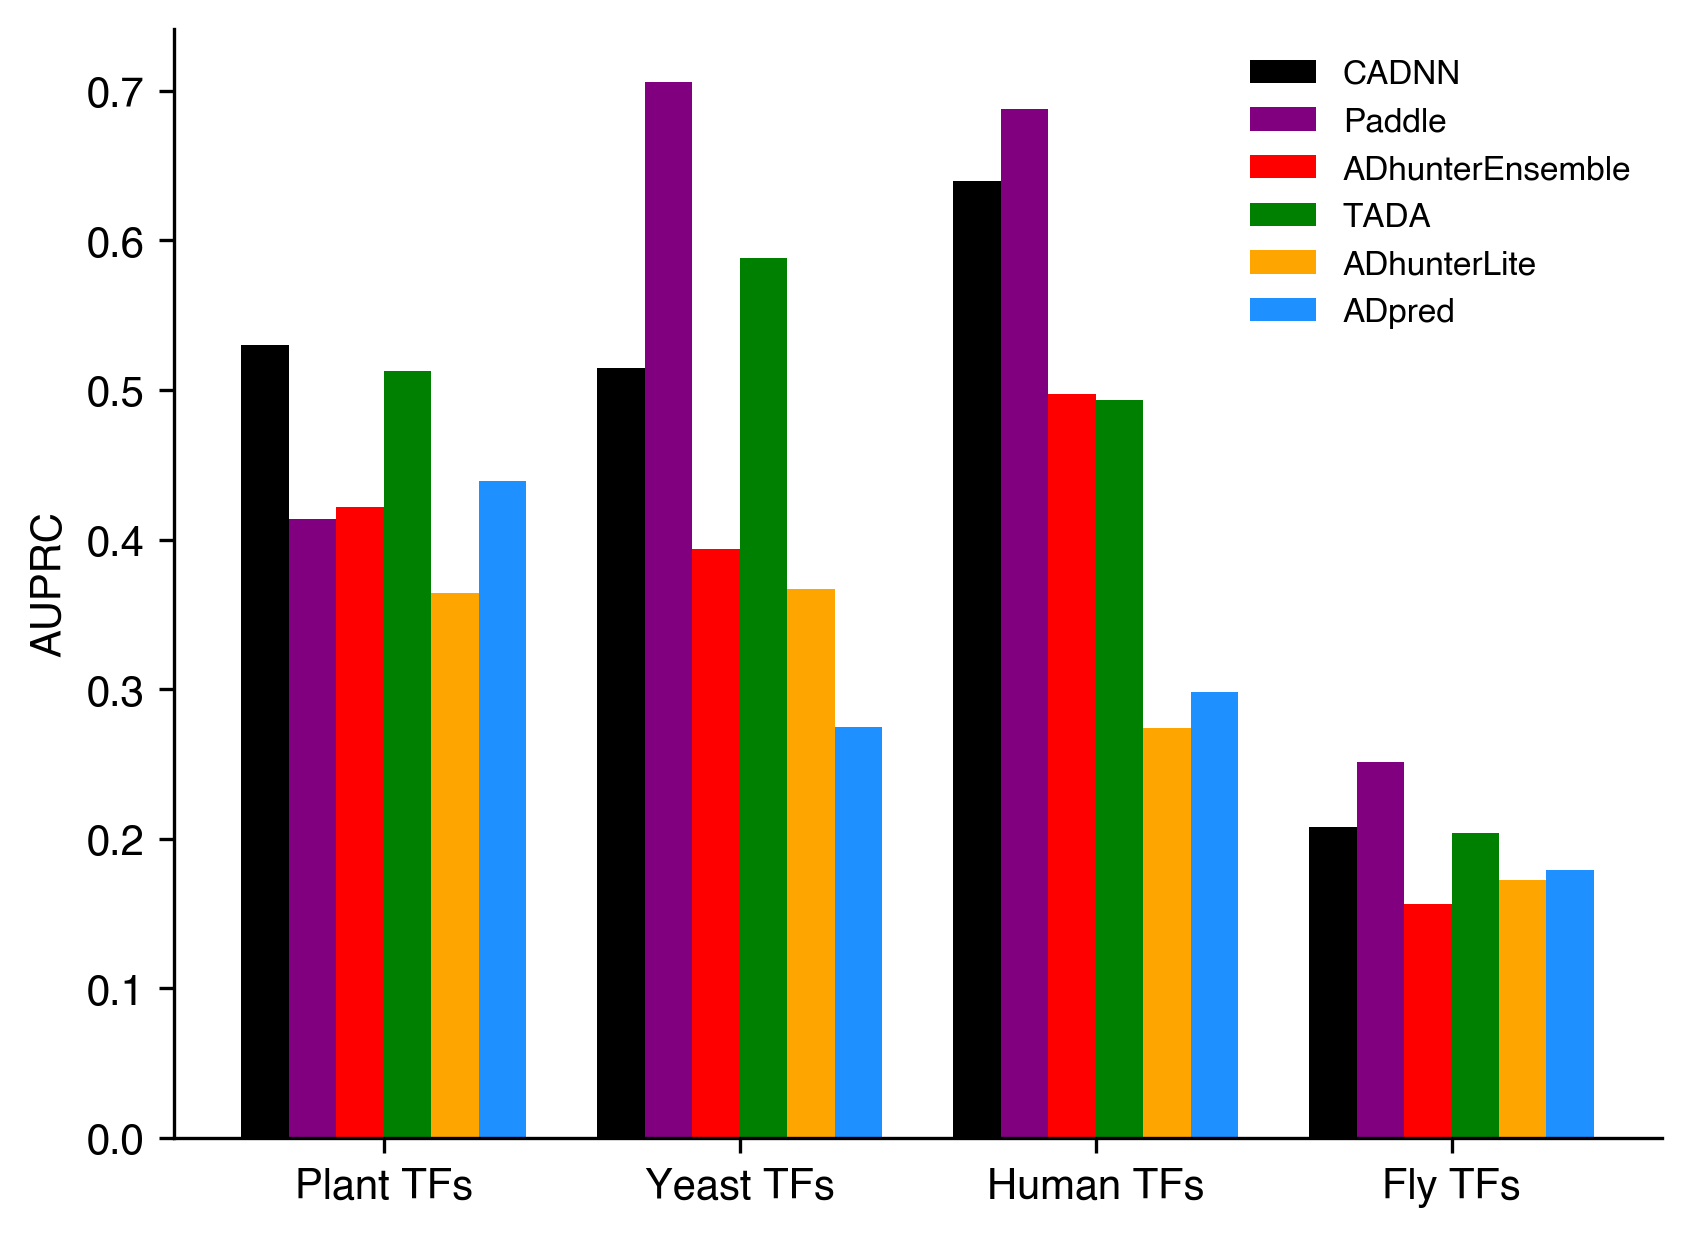

In [29]:
predictors = ['CADNN', 'Paddle', 'ADhunterEnsemble', 'TADA', 'ADhunterLite', 'ADpred']
groups = ['Plant TFs', 'Yeast TFs', 'Human TFs', 'Fly TFs']

# rows = groups, columns = predictors
data = np.array([
   # CADNN  PADDLE  ADE   TADA   ADL    ADPred
    # [0.527, 0.410, 0.409, 0.472, 0.334, 0.438],  # Plant
    [0.53, 0.414, 0.422, 0.513, 0.364, 0.439],  # Plant

    [0.515, 0.706, 0.394, 0.588, 0.367, 0.275],  # Yeast
    [0.640, 0.688, 0.497, 0.493, 0.274, 0.298],  # Human
    [0.208, 0.251, 0.156, 0.204, 0.1721, 0.179],  # Fly
])

n_groups, n_pred = data.shape
x = np.arange(n_groups)          # one slot per group
width = 0.8 / n_pred   

fig, ax = plt.subplots()
for i in range(n_pred):
    offset = (i - (n_pred - 1) / 2) * width   # center the cluster on the tick
    ax.bar(x + offset, data[:, i], width, label=predictors[i], color=color_dict[predictors[i]])

ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel('AUPRC')
ax.legend(ncol=1, fontsize=8, frameon=False)
sns.despine()

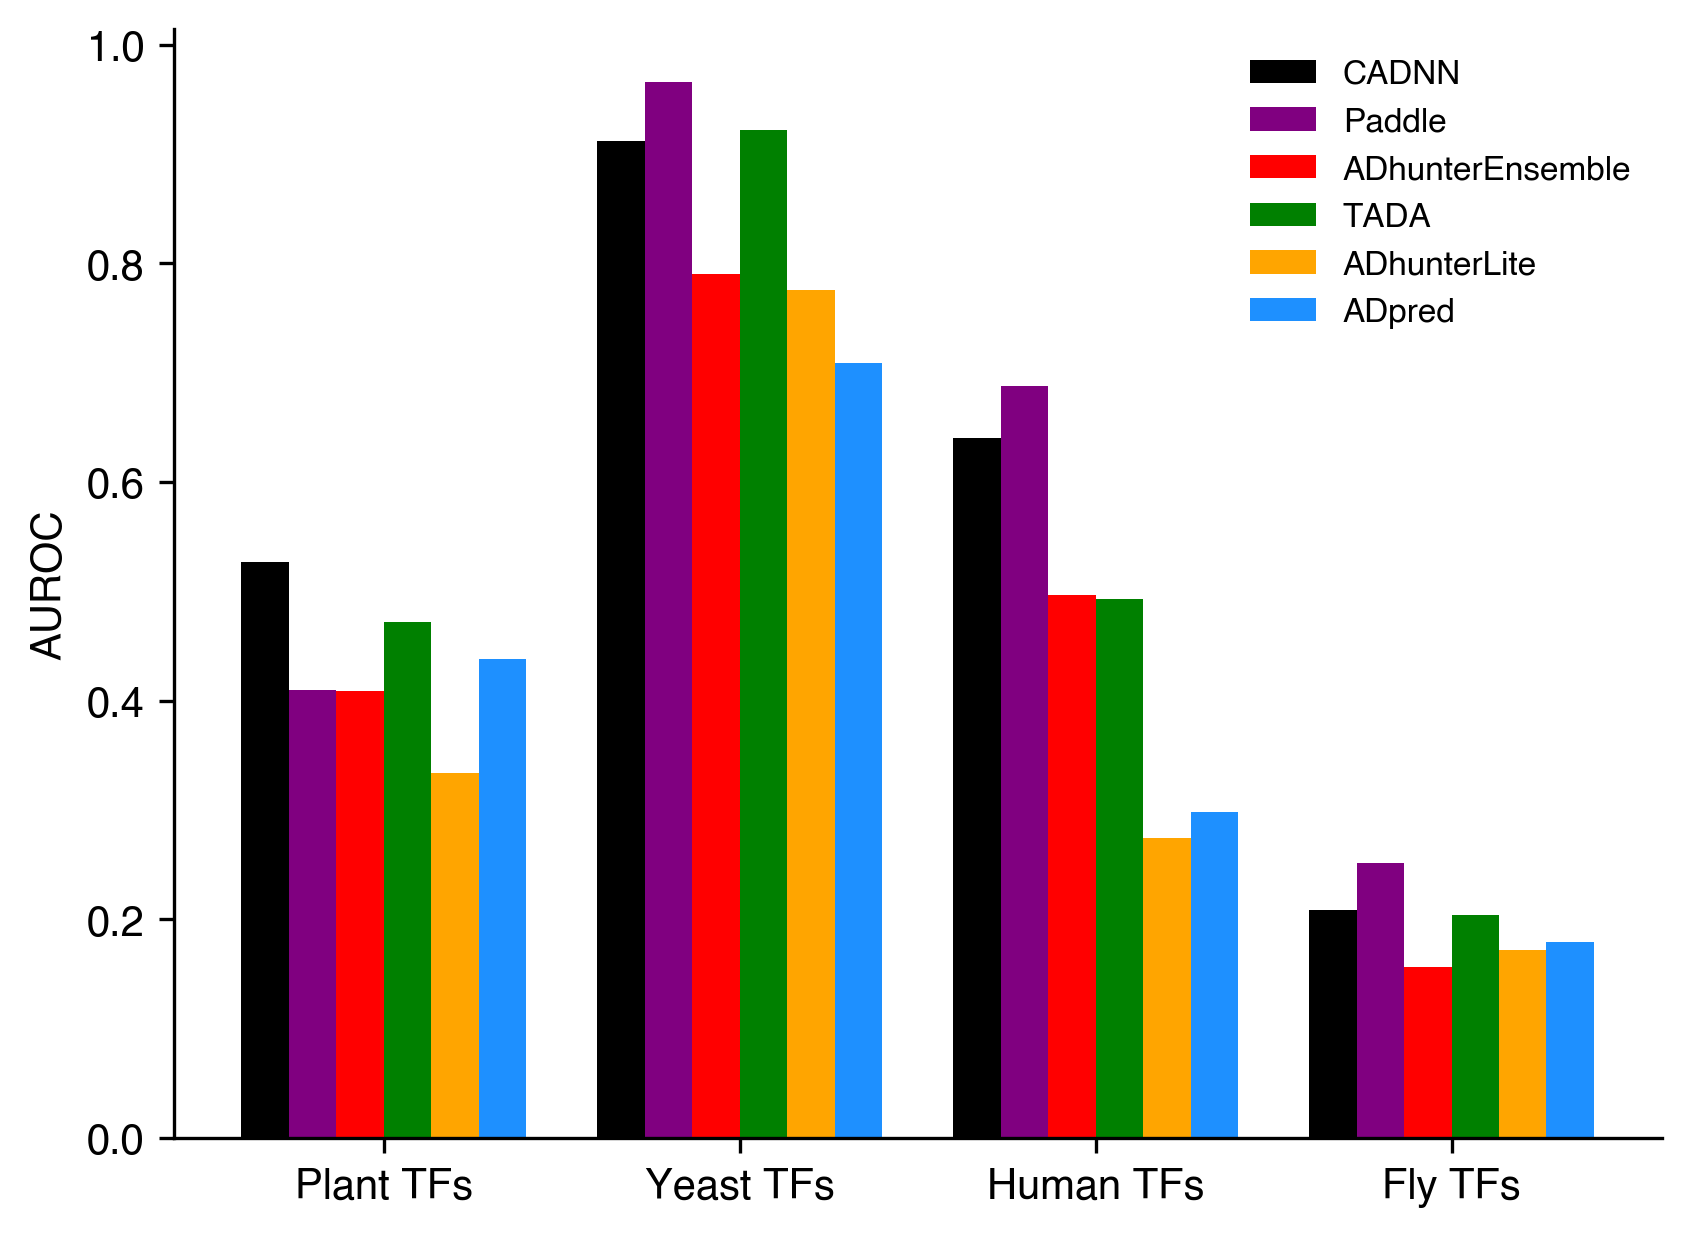

In [30]:
# From plant: 
#TADA ROC AUC: 0.922
# Parrot consensus ROC AUC: 0.912
# Paddle ROC AUC: 0.966
# ADhunterLite ROC AUC: 0.776
# ADhunterEnsemble ROC AUC: 0.79
# ADpred ROC AUC: 0.709

predictors = ['CADNN', 'Paddle', 'ADhunterEnsemble', 'TADA', 'ADhunterLite', 'ADpred']
groups = ['Plant TFs', 'Yeast TFs', 'Human TFs', 'Fly TFs']

# rows = groups, columns = predictors
data = np.array([
   # CADNN  PADDLE  ADE   TADA   ADL    ADPred
    [0.527, 0.410, 0.409, 0.472, 0.334, 0.438],  # Plant
    [0.912, 0.966, 0.79, 0.922, 0.776, 0.709],  # Yeast
    [0.640, 0.688, 0.497, 0.493, 0.274, 0.298],  # Human
    [0.208, 0.251, 0.156, 0.204, 0.1721, 0.179],  # Fly
])

n_groups, n_pred = data.shape
x = np.arange(n_groups)          # one slot per group
width = 0.8 / n_pred   

fig, ax = plt.subplots()
for i in range(n_pred):
    offset = (i - (n_pred - 1) / 2) * width   # center the cluster on the tick
    ax.bar(x + offset, data[:, i], width, label=predictors[i], color=color_dict[predictors[i]])

ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel('AUROC')
ax.legend(ncol=1, fontsize=8, frameon=False)
sns.despine()